# Total model performance across datasets

Rank-normalize reconstruction and binary encoding metrics, aggregate them within each dataset, and compare total model performance across the three datasets.

In [1]:
# Compare rank-normalized total model performance across datasets for the three datasets.
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load model metrics

In [2]:
# Load the data.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"

# Locate the Excel file in the notebook directory.
file_path = plm_res + "plm-bvae_metrics.xlsx"

# Load each sheet into a DataFrame.
peptide_df = pd.read_excel(file_path, sheet_name="peptide")
cdrh3_df   = pd.read_excel(file_path, sheet_name="CDRH3")
aav_df     = pd.read_excel(file_path, sheet_name="AAV")

# Drop the NLL, PPL, and total score columns.
peptide_df = peptide_df.drop(columns=['nll', 'ppl', 'S_total'])
cdrh3_df   = cdrh3_df.drop(columns=['nll', 'ppl', 'S_total'])
aav_df     = aav_df.drop(columns=['nll', 'ppl', 'S_total'])

# Remove line breaks from column names.
peptide_df = peptide_df.rename(columns=lambda x: x.replace(' \n', ' ').replace('\n', ' '))
cdrh3_df   = cdrh3_df.rename(columns=lambda x: x.replace(' \n', ' ').replace('\n', ' '))
aav_df     = aav_df.rename(columns=lambda x: x.replace(' \n', ' ').replace('\n', ' '))

# Convert columns other than model to float.
peptide_df[peptide_df.columns[peptide_df.columns != 'model']] = peptide_df.select_dtypes(include=[np.number])
cdrh3_df[cdrh3_df.columns[cdrh3_df.columns != 'model']] = cdrh3_df.select_dtypes(include=[np.number])
aav_df[aav_df.columns[aav_df.columns != 'model']] = aav_df.select_dtypes(include=[np.number])

# Reverse the sign of the BLOSUM62 versus Hamming Spearman correlation.
peptide_df['Spearman r of BLOSUM62 vs. Ham_dist'] = -peptide_df['Spearman r of BLOSUM62 vs. Ham_dist']
cdrh3_df['Spearman r of BLOSUM62 vs. Ham_dist'] = -cdrh3_df['Spearman r of BLOSUM62 vs. Ham_dist']
aav_df['Spearman r of BLOSUM62 vs. Ham_dist'] = -aav_df['Spearman r of BLOSUM62 vs. Ham_dist']

# Inspect the data.
display(peptide_df.tail())
display(cdrh3_df.head())
display(aav_df.head())

,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist
10,ESM2_3B-bVAE (HPO),0.972862,0.930921,0.445036,0.454839
11,ProtT5-bVAE (HPO),0.967928,0.937500,0.458436,0.540027
12,ProstT5-bVAE (HPO),0.972862,0.935855,0.434962,0.465506
13,Ankh_base-bVAE (HPO),0.976151,0.941612,0.454249,0.494847
14,Ankh_large-bVAE (HPO),0.972039,0.937500,0.443232,0.552195


,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist
0,bVAE,0.706250,0.054167,0.493083,0.470401
1,ESM2_8M-bVAE,0.862500,0.058333,0.447523,0.444021
2,ESM2_650M-bVAE,0.732292,0.047917,0.442781,0.455279
3,ESM2_3B-bVAE,0.540625,0.038542,0.487555,0.488711
4,ProtT5-bVAE,0.838542,0.056250,0.440795,0.434410


,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist
0,bVAE,0.000000,0.050746,0.104388,0.167983
1,ESM2_8M-bVAE,0.002388,0.132537,0.451944,0.552152
2,ESM2_650M-bVAE,0.000000,0.091343,0.550175,0.604452
3,ESM2_3B-bVAE,0.000000,0.062687,0.336090,0.480772
4,ProtT5-bVAE,0.000000,0.091940,0.499368,0.595489


## Rank-normalize each metric

In [3]:
# Rank-normalize each metric to the range from zero to one.
def rank_normalize(df):
    # Select all columns except model.
    cols_to_normalize = df.columns[df.columns != 'model']
    
    # Rank-normalize each metric.
    for col in cols_to_normalize:
        df[col] = df[col].rank(method='average')  # Calculate ranks.
        df[col] = (df[col] - 1) / (len(df) - 1)   # Scale ranks to the range from zero to one.
    
    return df

In [4]:
# Create the rank-normalized DataFrame.
peptide_df_normalized = rank_normalize(peptide_df.copy())
cdrh3_df_normalized = rank_normalize(cdrh3_df.copy())
aav_df_normalized = rank_normalize(aav_df.copy())

## Aggregate reconstruction and binary encoding scores

In [5]:
# Average the rank-normalized reconstruction metrics.
peptide_df_normalized['S_reconstruction'] = peptide_df_normalized[['The ratio of seqs with Lev_dist of 0', 'The ratio of seqs with BLOSUM62 of top 5%']].mean(axis=1)
cdrh3_df_normalized['S_reconstruction'] = cdrh3_df_normalized[['The ratio of seqs with Lev_dist of 0', 'The ratio of seqs with BLOSUM62 of top 5%']].mean(axis=1)
aav_df_normalized['S_reconstruction'] = aav_df_normalized[['The ratio of seqs with Lev_dist of 0', 'The ratio of seqs with BLOSUM62 of top 5%']].mean(axis=1)

# Average the rank-normalized binary encoding metrics.
peptide_df_normalized['S_correlation'] = peptide_df_normalized[['Spearman r of Lev_dist vs. Ham_dist', 'Spearman r of BLOSUM62 vs. Ham_dist']].mean(axis=1)
cdrh3_df_normalized['S_correlation'] = cdrh3_df_normalized[['Spearman r of Lev_dist vs. Ham_dist', 'Spearman r of BLOSUM62 vs. Ham_dist']].mean(axis=1)
aav_df_normalized['S_correlation'] = aav_df_normalized[['Spearman r of Lev_dist vs. Ham_dist', 'Spearman r of BLOSUM62 vs. Ham_dist']].mean(axis=1)

# Average the reconstruction and binary encoding scores to obtain total model performance.
peptide_df_normalized['S_total'] = peptide_df_normalized[['S_reconstruction', 'S_correlation']].mean(axis=1)
cdrh3_df_normalized['S_total'] = cdrh3_df_normalized[['S_reconstruction', 'S_correlation']].mean(axis=1)
aav_df_normalized['S_total'] = aav_df_normalized[['S_reconstruction', 'S_correlation']].mean(axis=1)

In [6]:
peptide_df_normalized

,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist,S_reconstruction,S_correlation,S_total
0,bVAE,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,ESM2_8M-bVAE,0.142857,0.142857,0.285714,0.142857,0.142857,0.214286,0.178571
2,ESM2_650M-bVAE,0.285714,0.321429,0.214286,0.071429,0.303571,0.142857,0.223214
3,ESM2_3B-bVAE,0.357143,0.321429,0.357143,0.285714,0.339286,0.321429,0.330357
4,ProtT5-bVAE,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571
5,ProstT5-bVAE,0.500000,0.500000,0.500000,0.642857,0.500000,0.571429,0.535714
6,Ankh_base-bVAE,0.214286,0.214286,0.142857,0.214286,0.214286,0.178571,0.196429
7,Ankh_large-bVAE,0.071429,0.071429,0.071429,0.357143,0.071429,0.214286,0.142857
8,ESM2_8M-bVAE (HPO),0.571429,0.642857,0.928571,0.928571,0.607143,0.928571,0.767857
9,ESM2_650M-bVAE (HPO),0.928571,0.928571,1.000000,1.000000,0.928571,1.000000,0.964286


In [7]:
cdrh3_df_normalized

,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist,S_reconstruction,S_correlation,S_total
0,bVAE,0.071429,0.250000,0.500000,0.357143,0.160714,0.428571,0.294643
1,ESM2_8M-bVAE,0.500000,0.464286,0.285714,0.142857,0.482143,0.214286,0.348214
2,ESM2_650M-bVAE,0.214286,0.071429,0.142857,0.285714,0.142857,0.214286,0.178571
3,ESM2_3B-bVAE,0.000000,0.000000,0.428571,0.428571,0.000000,0.428571,0.214286
4,ProtT5-bVAE,0.428571,0.357143,0.071429,0.071429,0.392857,0.071429,0.232143
5,ProstT5-bVAE,0.142857,0.250000,0.357143,0.500000,0.196429,0.428571,0.312500
6,Ankh_base-bVAE,0.285714,0.142857,0.214286,0.214286,0.214286,0.214286,0.214286
7,Ankh_large-bVAE,0.357143,0.464286,0.000000,0.000000,0.410714,0.000000,0.205357
8,ESM2_8M-bVAE (HPO),0.607143,0.571429,0.714286,0.714286,0.589286,0.714286,0.651786
9,ESM2_650M-bVAE (HPO),0.928571,0.928571,1.000000,0.928571,0.928571,0.964286,0.946429


In [8]:
aav_df_normalized

,model,The ratio of seqs with Lev_dist of 0,The ratio of seqs with BLOSUM62 of top 5%,Spearman r of Lev_dist vs. Ham_dist,Spearman r of BLOSUM62 vs. Ham_dist,S_reconstruction,S_correlation,S_total
0,bVAE,0.107143,0.000000,0.000000,0.000000,0.053571,0.000000,0.026786
1,ESM2_8M-bVAE,0.500000,0.357143,0.571429,0.714286,0.428571,0.642857,0.535714
2,ESM2_650M-bVAE,0.107143,0.142857,0.928571,0.928571,0.125000,0.928571,0.526786
3,ESM2_3B-bVAE,0.107143,0.071429,0.071429,0.214286,0.089286,0.142857,0.116071
4,ProtT5-bVAE,0.107143,0.214286,0.785714,0.857143,0.160714,0.821429,0.491071
5,ProstT5-bVAE,0.285714,0.285714,0.285714,0.571429,0.285714,0.428571,0.357143
6,Ankh_base-bVAE,0.392857,0.428571,0.714286,0.785714,0.410714,0.750000,0.580357
7,Ankh_large-bVAE,0.392857,0.500000,0.357143,0.428571,0.446429,0.392857,0.419643
8,ESM2_8M-bVAE (HPO),0.928571,1.000000,0.214286,0.142857,0.964286,0.178571,0.571429
9,ESM2_650M-bVAE (HPO),0.785714,0.785714,0.857143,0.642857,0.785714,0.750000,0.767857


## Average scores across datasets

In [9]:
# Average the dataset scores with equal weights.
all_df_normalized = pd.DataFrame()
all_df_normalized['model'] = peptide_df_normalized['model']
all_df_normalized['S_reconstruction'] = (peptide_df_normalized['S_reconstruction'] + cdrh3_df_normalized['S_reconstruction'] + aav_df_normalized['S_reconstruction']) / 3
all_df_normalized['S_correlation'] = (peptide_df_normalized['S_correlation'] + cdrh3_df_normalized['S_correlation'] + aav_df_normalized['S_correlation']) / 3
all_df_normalized['S_total'] = (peptide_df_normalized['S_total'] + cdrh3_df_normalized['S_total'] + aav_df_normalized['S_total']) / 3

In [10]:
all_df_normalized

,model,S_reconstruction,S_correlation,S_total
0,bVAE,0.071429,0.142857,0.107143
1,ESM2_8M-bVAE,0.351190,0.357143,0.354167
2,ESM2_650M-bVAE,0.190476,0.428571,0.309524
3,ESM2_3B-bVAE,0.142857,0.297619,0.220238
4,ProtT5-bVAE,0.327381,0.440476,0.383929
5,ProstT5-bVAE,0.327381,0.476190,0.401786
6,Ankh_base-bVAE,0.279762,0.380952,0.330357
7,Ankh_large-bVAE,0.309524,0.202381,0.255952
8,ESM2_8M-bVAE (HPO),0.720238,0.607143,0.663690
9,ESM2_650M-bVAE (HPO),0.880952,0.904762,0.892857


## Plot total model performance

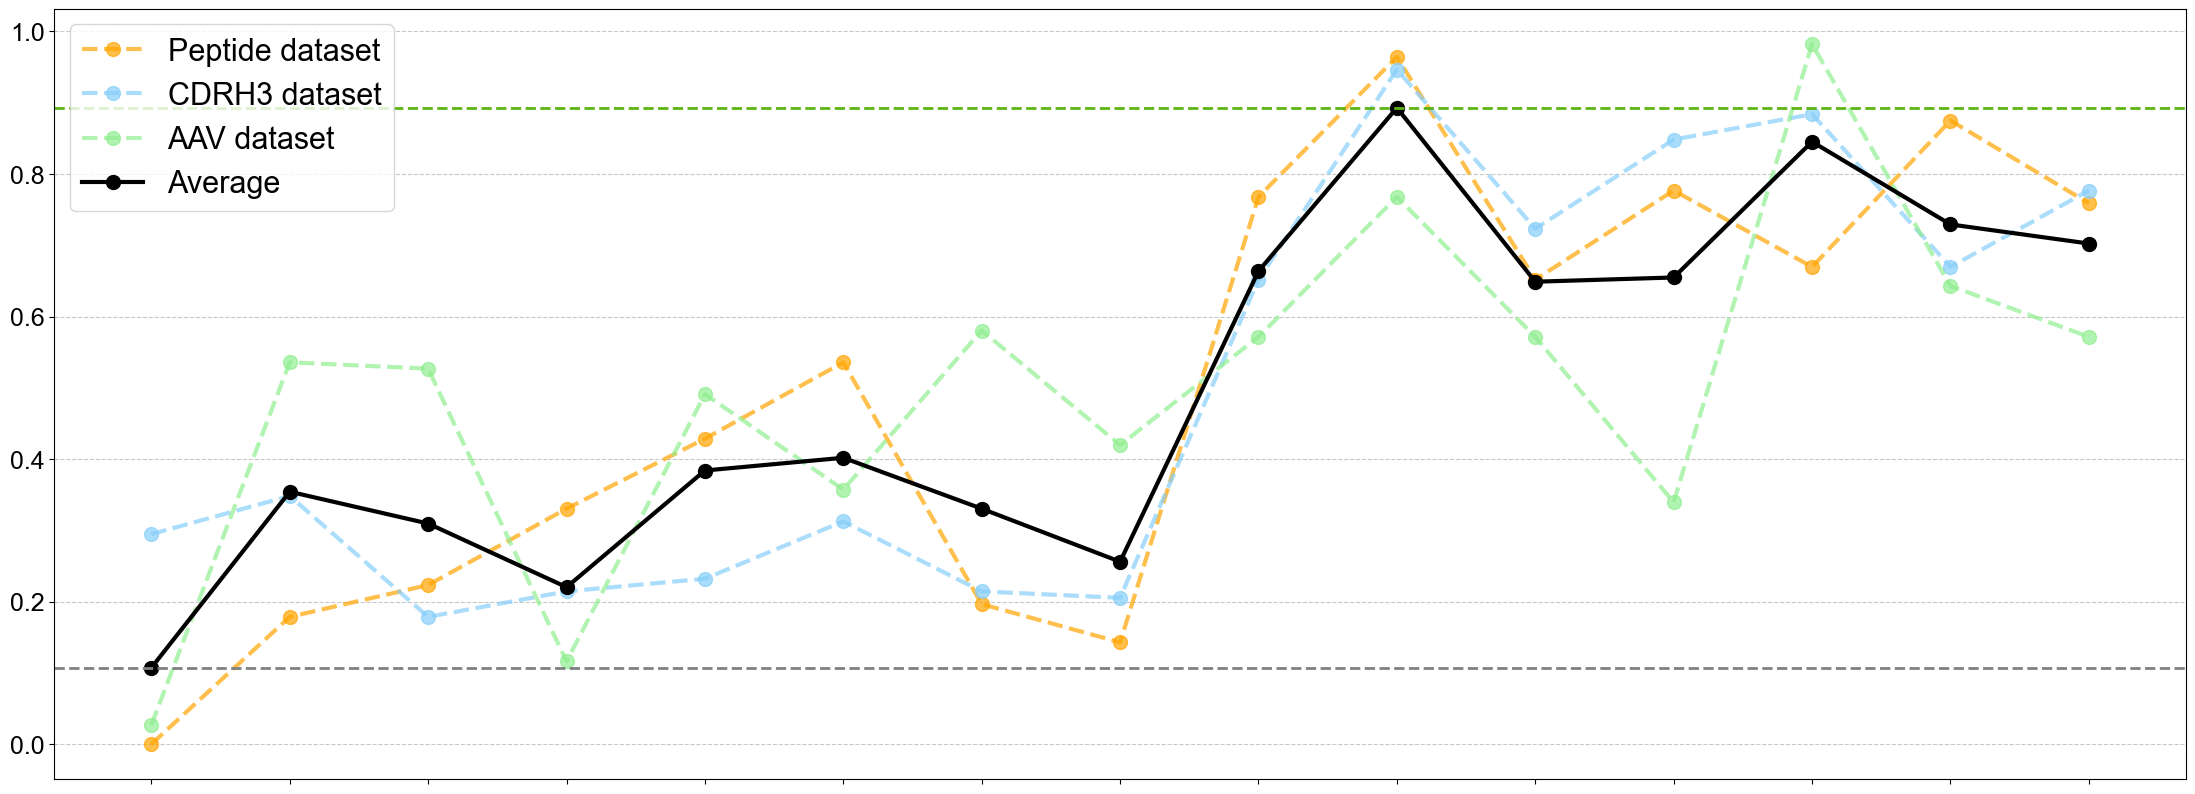

In [11]:
# Plot the total model performance across datasets.
plt.figure(figsize=(27.5, 10))
plt.plot(peptide_df_normalized['S_total'], marker='o', markersize=10, linewidth=3, ls='--', color='orange', alpha=0.7, label='Peptide dataset')
plt.plot(cdrh3_df_normalized['S_total'], marker='o', markersize=10, linewidth=3, ls='--', color='lightskyblue', alpha=0.7, label='CDRH3 dataset')
plt.plot(aav_df_normalized['S_total'], marker='o', markersize=10, linewidth=3, ls='--', color='lightgreen', alpha=0.7, label='AAV dataset')
plt.plot(all_df_normalized['S_total'], marker='o', markersize=10, linewidth=3, color='black', label='Average')

# Show the bVAE total score as a horizontal reference line.
bvae_value = all_df_normalized[all_df_normalized["model"] == "bVAE"]["S_total"].values[0]
plt.axhline(y=bvae_value, color='gray', linestyle='--', linewidth=2)
# Show the ESM2 650M result as a horizontal reference line.
esm_650m_value = all_df_normalized[all_df_normalized["model"] == "ESM2_650M-bVAE (HPO)"]["S_total"].values[0]
plt.axhline(y=esm_650m_value, color='#5CB514', linestyle='--', linewidth=2)
# Show the grid.
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks(ticks=np.arange(len(all_df_normalized)), labels='', rotation=45, ha='right', fontsize=18)
plt.yticks(fontsize=18)
plt.xlabel('', fontsize=22)
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=22, loc='upper left')
plt.show()